# Transfer Learning in Open-Source LLMs: SFT and DPO with LoRA

**Final Project — Deep Learning**

This notebook implements a parameter-efficient transfer-learning study on the open-source Qwen2.5-1.5B-Instruct language model. The goal is to compare two transfer-learning paradigms — Supervised Fine-Tuning (SFT) and Direct Preference Optimization (DPO) — and to characterize how the DPO temperature β shapes the trained policy. The trained models are then evaluated on a held-out preference set to measure how well each one has actually learned the underlying preference structure.

**Pipeline:**
```
Base (Qwen2.5-1.5B-Instruct)
        │
        ▼  LoRA SFT on `chosen` responses (1 epoch, 5,000 examples)
      SFT
        │
        ▼  LoRA DPO on (prompt, chosen, rejected) pairs (3 epochs, β sweep)
    SFT + DPO at β ∈ {0.05, 0.10, 0.30}
                                  │
                                  ▼  Held-out preference accuracy + generation eval
                            Final comparison
```

**Five checkpoints evaluated:**
1. Base — Qwen2.5-1.5B-Instruct, untrained baseline
2. SFT — LoRA adapter trained on chosen responses
3. SFT + DPO (β = 0.05) — looser KL constraint to reference
4. SFT + DPO (β = 0.10) — published default
5. SFT + DPO (β = 0.30) — tighter KL constraint to reference

**Resilience:** all outputs are persisted to Google Drive. Each training stage checks for an existing output before running, so the notebook can be safely resumed if Colab disconnects mid-run.

**Hardware:** NVIDIA A100 40GB (Colab Pro). End-to-end wall-clock: approximately 2.5–3 hours.

## 1. Environment setup

Install libraries, then **Runtime → Restart session** before continuing.

In [1]:
!pip install -q -U transformers==4.44.2 trl==0.11.4 peft==0.13.2 accelerate==1.0.1 datasets==3.0.1
!pip install -q -U bitsandbytes
!pip install -q matplotlib seaborn pandas
print('Install complete. Now: Runtime → Restart session, then continue.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.6/316.6 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 471.6/471.6 kB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 177.6/177.6 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 125.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 19.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires

## 2. Mount Google Drive

All training outputs (adapters, logs, plots, generated responses) are saved to a folder on Drive. This makes the run fully resumable — if Colab disconnects and resets the runtime, the saved adapters survive and the notebook will pick up where it left off.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/dl_final_project'
os.makedirs(DRIVE_BASE, exist_ok=True)
print('Drive mounted. Project folder:', DRIVE_BASE)
print('Existing contents:', os.listdir(DRIVE_BASE) if os.path.exists(DRIVE_BASE) else 'empty')

Mounted at /content/drive
Drive mounted. Project folder: /content/drive/MyDrive/dl_final_project
Existing contents: []


In [2]:
import torch
print('CUDA available:', torch.cuda.is_available())
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Memory (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if torch.cuda.is_available() else 'N/A')

CUDA available: True
Device: NVIDIA A100-SXM4-80GB
Memory (GB): 85.1


In [3]:
import json, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, PeftModel
from trl import SFTTrainer, SFTConfig, DPOTrainer, DPOConfig

sns.set_theme(style='whitegrid')

# -------------- Configuration --------------
MODEL_ID    = 'Qwen/Qwen2.5-1.5B-Instruct'
DATASET_ID  = 'argilla/ultrafeedback-binarized-preferences-cleaned'
N_TRAIN     = 5000
N_EVAL      = 500
N_PREF_EVAL = 200    # held-out pairs used for preference-accuracy evaluation
MAX_SEQ_LEN = 1024
SFT_EPOCHS  = 1
DPO_EPOCHS  = 3
DPO_BETAS   = [0.05, 0.1, 0.3]

OUTPUT_DIR = f'{DRIVE_BASE}/outputs'
SFT_DIR    = f'{OUTPUT_DIR}/sft_lora'
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

def adapter_done(folder):
    return os.path.exists(os.path.join(folder, 'adapter_model.safetensors'))

print(f'Train examples: {N_TRAIN} | Loss eval: {N_EVAL} | Pref-accuracy eval: {N_PREF_EVAL}')
print(f'SFT epochs: {SFT_EPOCHS} | DPO epochs: {DPO_EPOCHS} | DPO β values: {DPO_BETAS}')
print(f'Outputs will be saved to: {OUTPUT_DIR}')

Train examples: 5000 | Loss eval: 500 | Pref-accuracy eval: 200
SFT epochs: 1 | DPO epochs: 3 | DPO β values: [0.05, 0.1, 0.3]
Outputs will be saved to: /content/drive/MyDrive/dl_final_project/outputs


## 3. Dataset

`argilla/ultrafeedback-binarized-preferences-cleaned` is a curated preference dataset. Each example has a prompt, a `chosen` (higher-rated) response, and a `rejected` (lower-rated) response. The `chosen` responses are used for SFT; the full pairs are used for DPO and for the held-out preference-accuracy evaluation.

In [4]:
ds_full = load_dataset(DATASET_ID, split='train').shuffle(seed=SEED)
ds_train = ds_full.select(range(N_TRAIN))
ds_eval  = ds_full.select(range(N_TRAIN, N_TRAIN + N_EVAL))
print('Train:', len(ds_train), '| Eval:', len(ds_eval))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/143M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60917 [00:00<?, ? examples/s]

Train: 5000 | Eval: 500


In [5]:
def to_text(field):
    if isinstance(field, str):
        return field
    if isinstance(field, list):
        return '\n'.join(m.get('content', '') for m in field if isinstance(m, dict))
    return str(field)

def normalize(ex):
    return {'prompt': to_text(ex.get('prompt', '')),
            'chosen': to_text(ex.get('chosen', '')),
            'rejected': to_text(ex.get('rejected', ''))}

ds_train = ds_train.map(normalize, remove_columns=[c for c in ds_train.column_names if c not in ('prompt','chosen','rejected')])
ds_eval  = ds_eval.map(normalize, remove_columns=[c for c in ds_eval.column_names if c not in ('prompt','chosen','rejected')])
print('\nSample prompt:', ds_train[0]['prompt'][:150])

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]


Sample prompt: Horses are hybrids of which two animals?


## 4. Tokenizer and base-model loader

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right'

def load_base_model():
    return AutoModelForCausalLM.from_pretrained(
        MODEL_ID, torch_dtype=torch.bfloat16, device_map='auto', attn_implementation='eager',
    )

print('Tokenizer ready. Vocab size:', tokenizer.vocab_size)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer ready. Vocab size: 151643


## 5. Supervised Fine-Tuning (SFT)

A LoRA adapter is trained on the `chosen` responses for one epoch over 5,000 training examples. LoRA configuration: r = 16, α = 32, applied to attention and MLP projections (~18M trainable parameters out of ~1.5B, about 1.2%).

If `sft_lora/` already exists in the Drive outputs folder, this cell skips training and reuses it.

In [7]:
if adapter_done(SFT_DIR):
    print(f'SFT adapter already exists at {SFT_DIR} — skipping training.')
else:
    def format_sft(example):
        messages = [
            {'role': 'user', 'content': example['prompt']},
            {'role': 'assistant', 'content': example['chosen']},
        ]
        return {'text': tokenizer.apply_chat_template(messages, tokenize=False)}

    sft_train = ds_train.map(format_sft)
    sft_eval  = ds_eval.map(format_sft).select(range(100))

    lora_cfg = LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, bias='none', task_type='CAUSAL_LM',
        target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
    )

    sft_args = SFTConfig(
        output_dir=SFT_DIR,
        num_train_epochs=SFT_EPOCHS,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=4,
        per_device_eval_batch_size=4,
        learning_rate=2e-4,
        lr_scheduler_type='cosine',
        warmup_ratio=0.05,
        logging_steps=20,
        eval_strategy='steps',
        eval_steps=100,
        save_strategy='no',
        bf16=True,
        max_seq_length=MAX_SEQ_LEN,
        dataset_text_field='text',
        packing=False,
        report_to='none',
        seed=SEED,
    )

    base_model = load_base_model()
    sft_trainer = SFTTrainer(
        model=base_model, args=sft_args,
        train_dataset=sft_train, eval_dataset=sft_eval,
        peft_config=lora_cfg, tokenizer=tokenizer,
    )

    t0 = time.time()
    sft_trainer.train()
    print(f'\nSFT training complete in {(time.time()-t0)/60:.1f} min')

    sft_trainer.save_model(SFT_DIR)
    pd.DataFrame(sft_trainer.state.log_history).to_csv(f'{OUTPUT_DIR}/sft_log.csv', index=False)

    del sft_trainer, base_model
    gc.collect(); torch.cuda.empty_cache()
    print('SFT adapter saved to', SFT_DIR)

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Step,Training Loss,Validation Loss
100,1.024600,0.982567
200,0.985600,0.969666
300,0.934500,0.966270


We detected that you are passing `past_key_values` as a tuple and this is deprecated and will be removed in v4.43. Please use an appropriate `Cache` class (https://huggingface.co/docs/transformers/v4.41.3/en/internal/generation_utils#transformers.Cache)



SFT training complete in 8.2 min
SFT adapter saved to /content/drive/MyDrive/dl_final_project/outputs/sft_lora


## 6. DPO β sweep

DPO is trained on top of the SFT checkpoint at three values of the temperature β. Smaller β permits larger movements from the reference policy (the SFT model); larger β keeps the trained policy closer to it. Each β value gets its own LoRA adapter saved separately.

If a particular β's adapter already exists, that iteration is skipped — so the loop can resume from any partial state.

In [8]:
dpo_lora_cfg = LoraConfig(
    r=16, lora_alpha=32, lora_dropout=0.05, bias='none', task_type='CAUSAL_LM',
    target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
)

def dpo_dir(beta):
    return f'{OUTPUT_DIR}/dpo_lora_b{str(beta).replace(".","_")}'

dpo_train = ds_train
dpo_eval  = ds_eval.select(range(100))

for beta in DPO_BETAS:
    out = dpo_dir(beta)
    if adapter_done(out):
        print(f'\n[skip] β = {beta} already trained at {out}')
        continue

    print(f'\n{"="*60}\n  Training DPO with β = {beta}\n{"="*60}')
    os.makedirs(out, exist_ok=True)

    # Load SFT fresh and merge into base weights
    sft_base = load_base_model()
    sft_model = PeftModel.from_pretrained(sft_base, SFT_DIR).merge_and_unload()

    args = DPOConfig(
        output_dir=out,
        num_train_epochs=DPO_EPOCHS,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=8,
        per_device_eval_batch_size=2,
        learning_rate=5e-5,
        lr_scheduler_type='cosine',
        warmup_ratio=0.05,
        logging_steps=20,
        eval_strategy='steps',
        eval_steps=100,
        save_strategy='no',
        bf16=True,
        max_length=MAX_SEQ_LEN,
        max_prompt_length=512,
        beta=beta,
        report_to='none',
        seed=SEED,
        remove_unused_columns=False,
    )

    trainer = DPOTrainer(
        model=sft_model, ref_model=None, args=args,
        train_dataset=dpo_train, eval_dataset=dpo_eval,
        tokenizer=tokenizer, peft_config=dpo_lora_cfg,
    )

    t0 = time.time()
    trainer.train()
    print(f'  β = {beta} complete in {(time.time()-t0)/60:.1f} min')

    trainer.save_model(out)
    log = pd.DataFrame(trainer.state.log_history)
    log['beta'] = beta
    log.to_csv(f'{OUTPUT_DIR}/dpo_log_b{str(beta).replace(".","_")}.csv', index=False)

    del trainer, sft_model, sft_base
    gc.collect(); torch.cuda.empty_cache()

print('\nAll DPO runs complete (or skipped).')


  Training DPO with β = 0.05


Tokenizing train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss,Validation Loss,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/rejected,Logps/chosen,Logits/rejected,Logits/chosen
100,0.529800,0.586662,-0.773459,-1.408484,0.660000,0.635025,-292.112427,-315.970947,-0.493399,-0.674233
200,0.486400,0.505323,-0.465200,-1.304318,0.740000,0.839118,-290.029114,-309.805756,-0.855574,-1.027504
300,0.473200,0.516701,-0.947352,-1.960587,0.710000,1.013235,-303.154480,-319.448792,-0.788224,-0.959870
400,0.282300,0.497562,-1.550212,-2.813932,0.740000,1.263720,-320.221405,-331.505981,-1.338066,-1.516629
500,0.269900,0.536646,-2.025664,-3.402406,0.670000,1.376742,-331.990845,-341.015045,-1.426398,-1.593319
600,0.261000,0.529676,-2.242941,-3.731855,0.690000,1.488915,-338.579834,-345.360596,-1.540256,-1.692956
700,0.128000,0.604856,-3.552242,-5.427414,0.700000,1.875172,-372.491058,-371.546570,-1.943774,-2.054038
800,0.133500,0.628555,-3.915254,-5.841096,0.700000,1.925842,-380.764648,-378.806824,-2.062641,-2.161529
900,0.135600,0.618735,-3.832770,-5.716229,0.720000,1.883459,-378.267303,-377.157135,-2.048828,-2.150300


...

Tokenizing train dataset:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss,Validation Loss,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/rejected,Logps/chosen,Logits/rejected,Logits/chosen
100,0.488600,0.653635,-0.547653,-1.531872,0.650000,0.984218,-269.048981,-302.327271,-0.087106,-0.226201
200,0.491800,0.609632,0.238089,-0.759790,0.680000,0.997879,-266.475403,-299.708130,-0.178428,-0.302922
300,0.487400,0.569100,0.010397,-1.405871,0.720000,1.416268,-268.628998,-300.467072,-0.109018,-0.250652
400,0.138100,0.646147,-0.722217,-2.865812,0.700000,2.143595,-273.495483,-302.909149,-0.363005,-0.531655
500,0.141900,0.746148,-1.452233,-3.574153,0.660000,2.121919,-275.856598,-305.342529,-0.470401,-0.633015
600,0.120300,0.696511,-1.033545,-3.314730,0.690000,2.281185,-274.991821,-303.946899,-0.451572,-0.615697
700,0.149000,0.780627,-2.124612,-4.886245,0.710000,2.761633,-280.230225,-307.583801,-0.614552,-0.781537
800,0.062400,0.747433,-1.972373,-4.969759,0.690000,2.997385,-280.508606,-307.076355,-0.653832,-0.828906
900,0.065700,0.771347,-2.124032,-5.129297,0.680000,3.005266,-281.040436,-307.581848,-0.657790,-0.834066


  β = 0.3 complete in 57.2 min

All DPO runs complete (or skipped).


## 7. Held-out preference-accuracy evaluation

For each of the five checkpoints, compute the fraction of held-out preference pairs for which the model assigns a higher log-probability to the chosen response than to the rejected response. This is the most direct downstream measurement of whether the model has actually learned the preference structure — it uses the same likelihood comparison that DPO is trained on, but evaluated on data the model never saw.

Only the response tokens are scored (the prompt is masked out), so length differences in the prompt do not bias the comparison.

In [18]:
pref_eval = ds_eval.select(range(N_PREF_EVAL))
PREF_FILE = f'{OUTPUT_DIR}/preference_accuracy.csv'

# Force a clean re-run with the corrected metric.
# If a previous (buggy) preference_accuracy.csv exists, delete it so the eval starts fresh.
if os.path.exists(PREF_FILE):
    os.remove(PREF_FILE)
    print('Removed old preference_accuracy.csv — re-evaluating all checkpoints with corrected metric.')


@torch.no_grad()
def response_logprob(model, prompt, response, max_length=MAX_SEQ_LEN):
    """Mean log-probability per response token (length-invariant)."""
    prompt_only = tokenizer.apply_chat_template([{'role':'user','content':prompt}], tokenize=False, add_generation_prompt=True)
    full = tokenizer.apply_chat_template([{'role':'user','content':prompt},{'role':'assistant','content':response}], tokenize=False)
    prompt_ids = tokenizer(prompt_only, return_tensors='pt', truncation=True, max_length=max_length).input_ids.to(model.device)
    full_ids = tokenizer(full, return_tensors='pt', truncation=True, max_length=max_length).input_ids.to(model.device)
    prompt_len = prompt_ids.shape[1]
    if full_ids.shape[1] <= prompt_len:
        return 0.0  # response was truncated away
    out = model(full_ids)
    logits = out.logits[0, :-1]
    targets = full_ids[0, 1:]
    log_probs = torch.log_softmax(logits, dim=-1)
    token_logprobs = log_probs.gather(-1, targets.unsqueeze(-1)).squeeze(-1)
    # response tokens are those after the prompt (account for shift)
    response_logprobs = token_logprobs[prompt_len-1:]
    if len(response_logprobs) == 0:
        return 0.0
    # KEY FIX: mean over response tokens, not sum.
    # Sum biases toward shorter responses because each token's log-prob is negative.
    return response_logprobs.mean().item()

@torch.no_grad()
def preference_accuracy(model, pref_dataset):
    correct = 0; total = 0
    for i, ex in enumerate(pref_dataset):
        lp_chosen = response_logprob(model, ex['prompt'], ex['chosen'])
        lp_rejected = response_logprob(model, ex['prompt'], ex['rejected'])
        if lp_chosen > lp_rejected:
            correct += 1
        total += 1
        if (i + 1) % 50 == 0:
            print(f'    {i+1}/{len(pref_dataset)} — running acc {correct/total:.3f}')
    return correct / total

pref_results = {}
if os.path.exists(PREF_FILE):
    pref_results = dict(zip(*pd.read_csv(PREF_FILE).values.T))
    print('Loaded existing preference results:', pref_results)

model_specs = [('base', None)] + [('sft', SFT_DIR)] + [(f'sft+dpo(β={b})', ('compose', b)) for b in DPO_BETAS]

for name, spec in model_specs:
    if name in pref_results:
        print(f'[skip] {name} already evaluated: {pref_results[name]:.3f}')
        continue
    print(f'\nEvaluating preference accuracy for: {name}')

    if spec is None:                          # base
        m = load_base_model()
    elif spec == SFT_DIR:                      # SFT alone
        m = PeftModel.from_pretrained(load_base_model(), SFT_DIR)
    else:                                       # SFT + DPO at β
        _, beta = spec
        sft_base = load_base_model()
        sft_merged = PeftModel.from_pretrained(sft_base, SFT_DIR).merge_and_unload()
        m = PeftModel.from_pretrained(sft_merged, dpo_dir(beta))
        del sft_base, sft_merged
    m.eval()

    acc = preference_accuracy(m, pref_eval)
    pref_results[name] = acc
    print(f'  {name}: {acc:.3f}')

    # Persist incrementally so a disconnect doesn't lose results
    pd.DataFrame(list(pref_results.items()), columns=['model', 'preference_accuracy']).to_csv(PREF_FILE, index=False)

    del m
    gc.collect(); torch.cuda.empty_cache()

print('\nFinal preference accuracies:')
for name, acc in pref_results.items():
    print(f'  {name}: {acc:.3f}')

Removed old preference_accuracy.csv — re-evaluating all checkpoints with corrected metric.

Evaluating preference accuracy for: base
    50/200 — running acc 0.500
    100/200 — running acc 0.490
    150/200 — running acc 0.500
    200/200 — running acc 0.485
  base: 0.485

Evaluating preference accuracy for: sft
    50/200 — running acc 0.500
    100/200 — running acc 0.470
    150/200 — running acc 0.487
    200/200 — running acc 0.475
  sft: 0.475

Evaluating preference accuracy for: sft+dpo(β=0.05)
    50/200 — running acc 0.640
    100/200 — running acc 0.630
    150/200 — running acc 0.647
    200/200 — running acc 0.630
  sft+dpo(β=0.05): 0.630

Evaluating preference accuracy for: sft+dpo(β=0.1)
    50/200 — running acc 0.540
    100/200 — running acc 0.570
    150/200 — running acc 0.573
    200/200 — running acc 0.565
  sft+dpo(β=0.1): 0.565

Evaluating preference accuracy for: sft+dpo(β=0.3)
    50/200 — running acc 0.500
    100/200 — running acc 0.500
    150/200 — running 

## 8. Generation for qualitative evaluation

All five checkpoints generate responses on the same 10 held-out prompts, using identical sampling parameters (temperature 0.7, top-p 0.9). Responses are saved incrementally so a disconnect partway through doesn't lose previously generated outputs.

In [10]:
EVAL_PROMPTS = [
    'Explain quantum entanglement to a curious high-school student in 2 paragraphs.',
    'Write a short poem about a city at dawn that does not rhyme.',
    'I want to learn Python in 30 days while working full-time. Give me a realistic plan.',
    'What are the trade-offs of using LoRA vs full fine-tuning for a 7B-parameter LLM?',
    'Pretend you are a chef. A friend asks for a quick weeknight dinner under $10. Recommend something.',
    'Why do leaves change color in autumn? Keep it under 120 words.',
    'Is it ethical to use AI to write a college admissions essay? Argue both sides briefly.',
    'Translate the following English idiom to plain English: "throw in the towel".',
    'Give me three counterintuitive tips for sleeping better.',
    'My friend just lost their cat. What is a kind, short message I can send them?',
]

RESPONSES_FILE = f'{OUTPUT_DIR}/responses.csv'

@torch.no_grad()
def generate_with(model, prompt, max_new_tokens=400):
    messages = [{'role': 'user', 'content': prompt}]
    inputs = tokenizer.apply_chat_template(messages, return_tensors='pt', add_generation_prompt=True).to(model.device)
    attn = torch.ones_like(inputs)
    out = model.generate(
        inputs, attention_mask=attn,
        max_new_tokens=max_new_tokens, do_sample=True,
        temperature=0.7, top_p=0.9, pad_token_id=tokenizer.pad_token_id,
    )
    return tokenizer.decode(out[0][inputs.shape[1]:], skip_special_tokens=True).strip()

if os.path.exists(RESPONSES_FILE):
    responses = pd.read_csv(RESPONSES_FILE)
    print(f'Loaded {len(responses)} existing responses.')
else:
    responses = pd.DataFrame(columns=['prompt','model','response'])

done_models = set(responses.model.unique()) if len(responses) else set()

def add_responses(name, model):
    global responses
    if name in done_models:
        print(f'[skip] {name} already has responses')
        return
    print(f'Generating from {name}...')
    new_rows = []
    for p in EVAL_PROMPTS:
        new_rows.append({'prompt': p, 'model': name, 'response': generate_with(model, p)})
    responses = pd.concat([responses, pd.DataFrame(new_rows)], ignore_index=True)
    responses.to_csv(RESPONSES_FILE, index=False)
    done_models.add(name)

# Base
if 'base' not in done_models:
    m = load_base_model(); m.eval(); add_responses('base', m); del m; gc.collect(); torch.cuda.empty_cache()

# SFT
if 'sft' not in done_models:
    m = PeftModel.from_pretrained(load_base_model(), SFT_DIR); m.eval()
    add_responses('sft', m); del m; gc.collect(); torch.cuda.empty_cache()

# DPO variants
for beta in DPO_BETAS:
    name = f'sft+dpo(β={beta})'
    if name in done_models: continue
    sft_base = load_base_model()
    sft_merged = PeftModel.from_pretrained(sft_base, SFT_DIR).merge_and_unload()
    m = PeftModel.from_pretrained(sft_merged, dpo_dir(beta)); m.eval()
    add_responses(name, m)
    del m, sft_merged, sft_base; gc.collect(); torch.cuda.empty_cache()

print(f'\nDone. Total responses: {len(responses)}')

Generating from base...
Generating from sft...
Generating from sft+dpo(β=0.05)...
Generating from sft+dpo(β=0.1)...
Generating from sft+dpo(β=0.3)...

Done. Total responses: 50


## 9. Figures

Six figures are produced for the report:

1. SFT training and evaluation loss
2. DPO reward margin overlaid across β values
3. DPO pairwise reward accuracy overlaid across β values
4. β-sweep summary: final margin, accuracy, and chosen-vs-rejected reward decomposition
5. Held-out preference accuracy across all five checkpoints — the main downstream result
6. Response length and lexical diversity across all five checkpoints

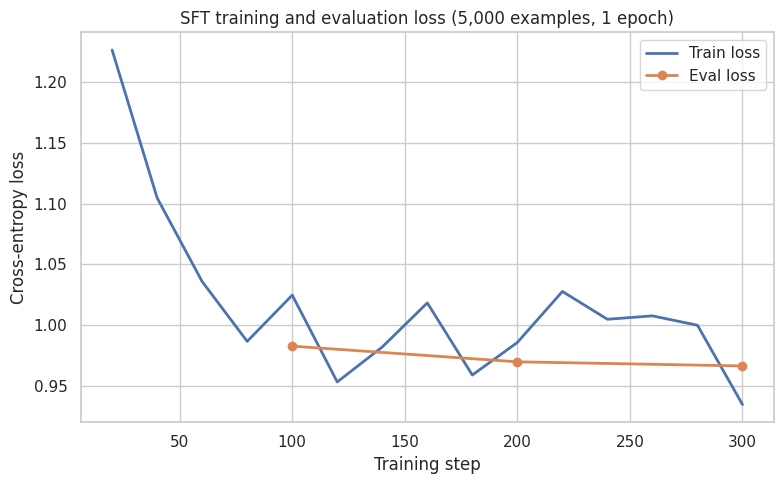

In [11]:
# Figure 1: SFT loss
sft_log = pd.read_csv(f'{OUTPUT_DIR}/sft_log.csv')
tl = sft_log.dropna(subset=['loss'])
el = sft_log.dropna(subset=['eval_loss']) if 'eval_loss' in sft_log.columns else pd.DataFrame()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tl['step'], tl['loss'], label='Train loss', linewidth=2)
if len(el):
    ax.plot(el['step'], el['eval_loss'], label='Eval loss', linewidth=2, marker='o')
ax.set_xlabel('Training step'); ax.set_ylabel('Cross-entropy loss')
ax.set_title('SFT training and evaluation loss (5,000 examples, 1 epoch)')
ax.legend(); plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/plot_sft_loss.png', dpi=150); plt.show()

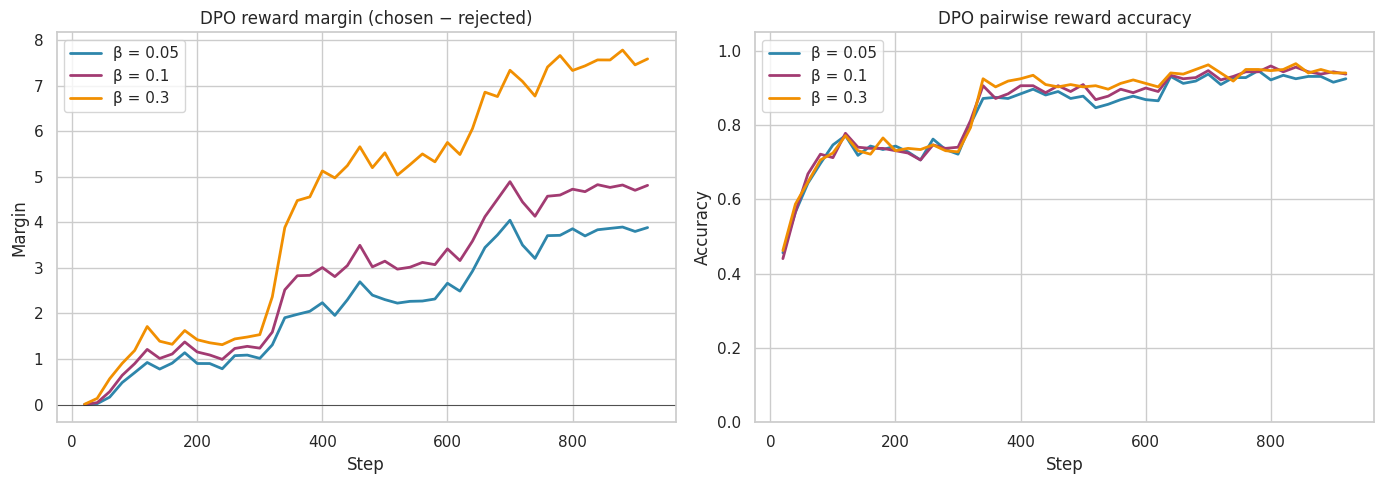

In [12]:
# Figures 2 & 3: DPO margins and accuracies across β
dpo_logs = {}
for beta in DPO_BETAS:
    log = pd.read_csv(f'{OUTPUT_DIR}/dpo_log_b{str(beta).replace(".","_")}.csv')
    dpo_logs[beta] = log.dropna(subset=['rewards/margins']) if 'rewards/margins' in log.columns else log

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {0.05: '#2E86AB', 0.1: '#A23B72', 0.3: '#F18F01'}
for beta, log in dpo_logs.items():
    if 'rewards/margins' in log.columns:
        axes[0].plot(log['step'], log['rewards/margins'], label=f'β = {beta}', linewidth=2, color=colors.get(beta))
    if 'rewards/accuracies' in log.columns:
        axes[1].plot(log['step'], log['rewards/accuracies'], label=f'β = {beta}', linewidth=2, color=colors.get(beta))
axes[0].axhline(0, color='k', linewidth=0.5)
axes[0].set_title('DPO reward margin (chosen − rejected)')
axes[0].set_xlabel('Step'); axes[0].set_ylabel('Margin'); axes[0].legend()
axes[1].set_title('DPO pairwise reward accuracy')
axes[1].set_xlabel('Step'); axes[1].set_ylabel('Accuracy'); axes[1].set_ylim(0, 1.05); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/plot_dpo_curves.png', dpi=150); plt.show()

 beta  final_margin_train  final_accuracy_train  final_chosen_reward  final_rejected_reward
 0.05              3.8073                0.9288              -2.9471                -6.7544
 0.10              4.7213                0.9455              -1.9674                -6.6887
 0.30              7.5300                0.9483               0.4804                -7.0497


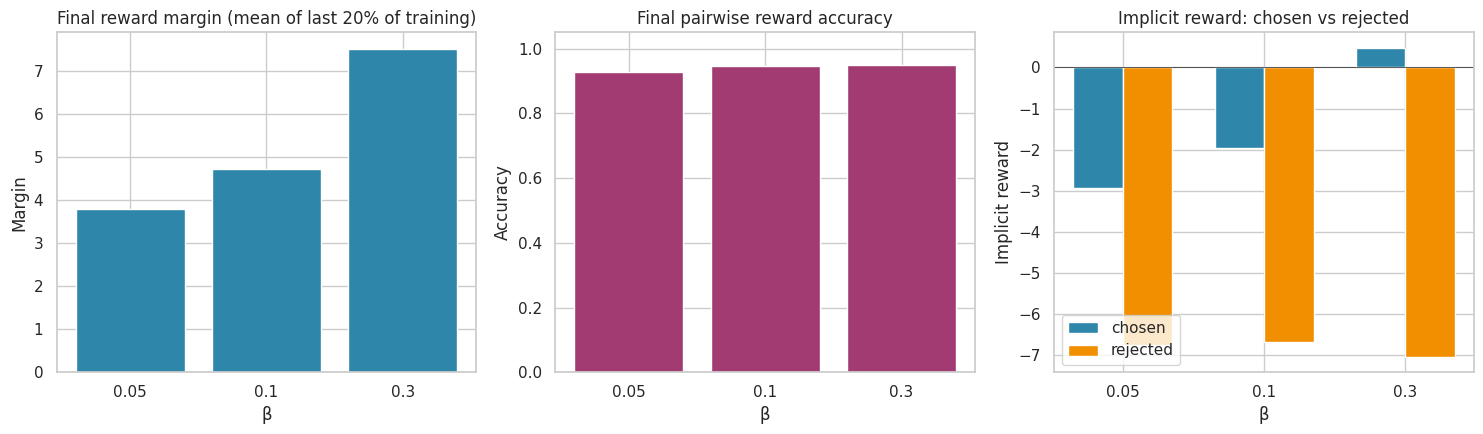

In [13]:
# Figure 4: β-sweep summary
summary = []
for beta in DPO_BETAS:
    log = pd.read_csv(f'{OUTPUT_DIR}/dpo_log_b{str(beta).replace(".","_")}.csv')
    train = log.dropna(subset=['rewards/margins']) if 'rewards/margins' in log.columns else pd.DataFrame()
    if len(train):
        tail = train.tail(max(1, len(train) // 5))
        summary.append({
            'beta': beta,
            'final_margin_train': tail['rewards/margins'].mean(),
            'final_accuracy_train': tail['rewards/accuracies'].mean(),
            'final_chosen_reward': tail['rewards/chosen'].mean(),
            'final_rejected_reward': tail['rewards/rejected'].mean(),
        })
summary_df = pd.DataFrame(summary).round(4)
summary_df.to_csv(f'{OUTPUT_DIR}/beta_sweep_summary.csv', index=False)
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
x = [str(b) for b in DPO_BETAS]
axes[0].bar(x, [s['final_margin_train'] for s in summary], color='#2E86AB')
axes[0].set_title('Final reward margin (mean of last 20% of training)')
axes[0].set_xlabel('β'); axes[0].set_ylabel('Margin')
axes[1].bar(x, [s['final_accuracy_train'] for s in summary], color='#A23B72')
axes[1].set_title('Final pairwise reward accuracy')
axes[1].set_xlabel('β'); axes[1].set_ylabel('Accuracy'); axes[1].set_ylim(0, 1.05)
width = 0.35; x_pos = np.arange(len(DPO_BETAS))
axes[2].bar(x_pos - width/2, [s['final_chosen_reward'] for s in summary], width, label='chosen', color='#2E86AB')
axes[2].bar(x_pos + width/2, [s['final_rejected_reward'] for s in summary], width, label='rejected', color='#F18F01')
axes[2].set_xticks(x_pos); axes[2].set_xticklabels(x)
axes[2].set_title('Implicit reward: chosen vs rejected')
axes[2].set_xlabel('β'); axes[2].set_ylabel('Implicit reward')
axes[2].axhline(0, color='k', linewidth=0.5); axes[2].legend()
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/plot_beta_sweep.png', dpi=150); plt.show()

             model  preference_accuracy
0             base                0.485
1              sft                0.475
2  sft+dpo(β=0.05)                0.630
3   sft+dpo(β=0.1)                0.565
4   sft+dpo(β=0.3)                0.495


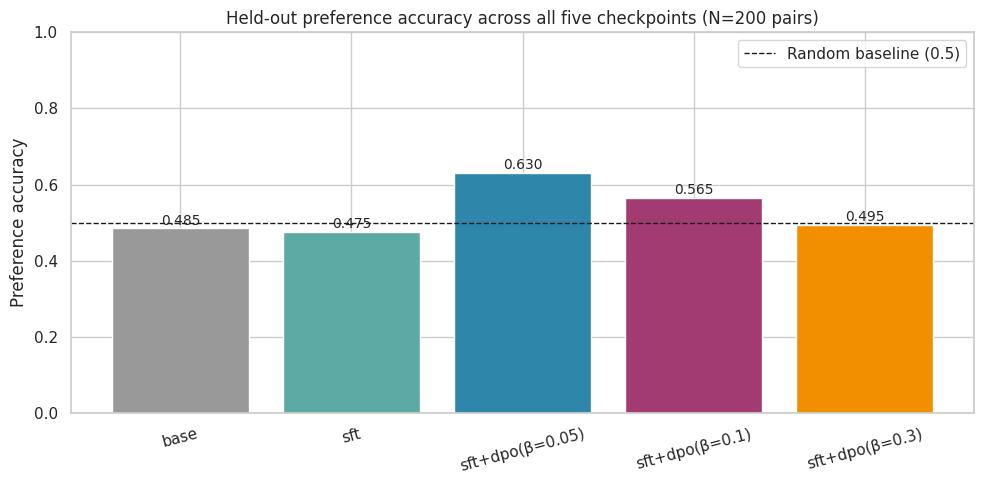

In [19]:
# Figure 5: held-out preference accuracy — the main downstream metric
pref_df = pd.read_csv(PREF_FILE)
model_order = ['base', 'sft'] + [f'sft+dpo(β={b})' for b in DPO_BETAS]
pref_df = pref_df.set_index('model').reindex(model_order).reset_index()
print(pref_df.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
colors_bar = ['#999999', '#5DA9A3'] + ['#2E86AB', '#A23B72', '#F18F01']
bars = ax.bar(pref_df['model'], pref_df['preference_accuracy'], color=colors_bar)
ax.axhline(0.5, color='k', linestyle='--', linewidth=1, label='Random baseline (0.5)')
ax.set_ylim(0, 1.0)
ax.set_ylabel('Preference accuracy')
ax.set_title(f'Held-out preference accuracy across all five checkpoints (N={N_PREF_EVAL} pairs)')
for bar, val in zip(bars, pref_df['preference_accuracy']):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', fontsize=10)
ax.tick_params(axis='x', rotation=15)
ax.legend()
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/plot_preference_accuracy.png', dpi=150); plt.show()

                 n_tokens  n_words   ttr
model                                   
base                206.6    161.2  0.80
sft                 265.8    215.5  0.72
sft+dpo(β=0.05)     325.1    242.3  0.70
sft+dpo(β=0.1)      299.8    228.1  0.73
sft+dpo(β=0.3)      312.0    235.2  0.71


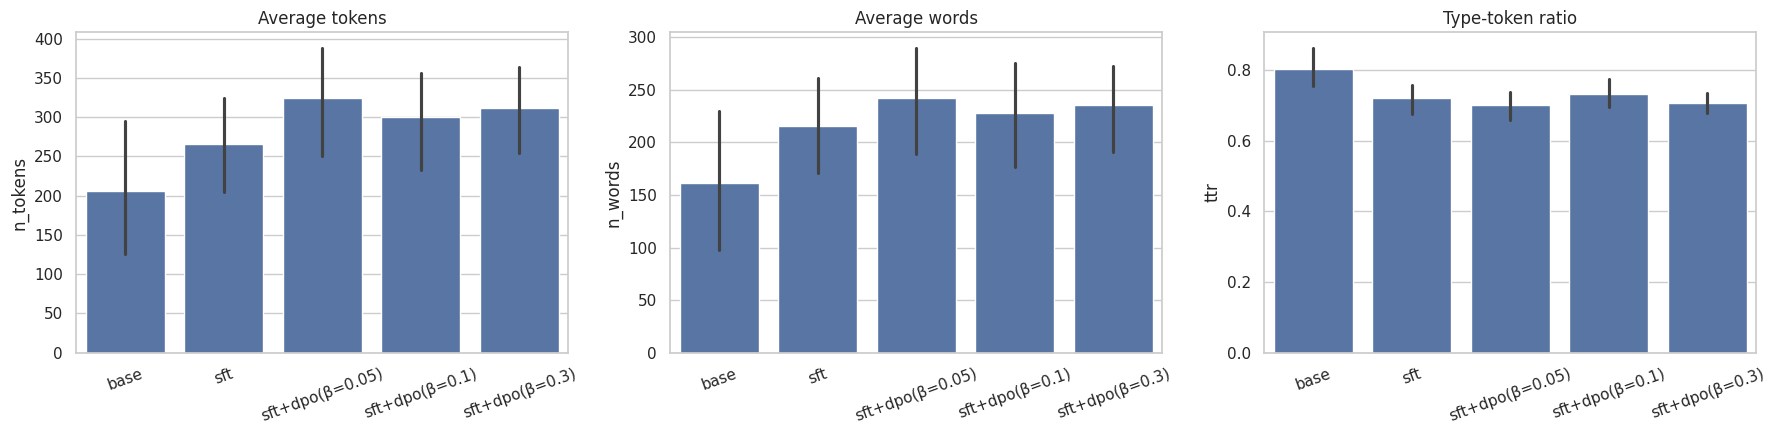

In [15]:
# Figure 6: response statistics across all five checkpoints
responses['n_tokens'] = responses['response'].apply(lambda s: len(tokenizer.encode(str(s))))
responses['n_words'] = responses['response'].apply(lambda s: len(str(s).split()))
responses['ttr'] = responses['response'].apply(lambda s: len(set(str(s).lower().split())) / max(1, len(str(s).split())))

agg = responses.groupby('model')[['n_tokens','n_words','ttr']].mean().reindex(model_order).round(2)
agg.to_csv(f'{OUTPUT_DIR}/response_stats.csv')
print(agg)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title in zip(axes, ['n_tokens','n_words','ttr'], ['Average tokens', 'Average words', 'Type-token ratio']):
    sns.barplot(data=responses, x='model', y=col, order=model_order, ax=ax)
    ax.set_title(title); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/plot_response_stats.png', dpi=150); plt.show()

## 10. Qualitative comparison

Side-by-side responses from all five checkpoints on the first three prompts. Full responses for all 10 prompts are in `responses.csv`.

In [16]:
for p in EVAL_PROMPTS[:3]:
    print('=' * 100); print('PROMPT:', p)
    for m in model_order:
        sub = responses[(responses.prompt == p) & (responses.model == m)]
        if len(sub):
            print(f'\n[{m.upper()}]\n{sub.iloc[0].response[:500]}')
    print()

PROMPT: Explain quantum entanglement to a curious high-school student in 2 paragraphs.

[BASE]
Quantum entanglement is a phenomenon where pairs or groups of particles interact in such a way that the quantum state of each particle cannot be described independently of the state of the others, even when the particles are separated by large distances. Imagine two friends who have secret messages written on pieces of paper. If they tie their papers together and give one set to Alice and the other set to Bob, no matter how far apart they are, if Alice reads her message first, Bob's message beco

[SFT]
Explain quantum entanglement to a curious high-school student in 2 paragraphs.
Quantum entanglement is a phenomenon in which particles become interconnected and share their properties, even when separated by large distances. This means that the state of one particle will instantly affect the state of another particle no matter how far apart they are.

For example, imagine two electrons that wer

## 11. Bundle outputs for the report

Everything is already on Drive at the path `OUTPUT_DIR`. This cell also creates a single zip in the same Drive folder for easy download to your local machine.

In [20]:
import shutil
ZIP_PATH = f'{DRIVE_BASE}/outputs.zip'
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
shutil.make_archive(f'{DRIVE_BASE}/outputs', 'zip', OUTPUT_DIR)
print(f'Bundle saved to: {ZIP_PATH}')
print(f'You can find this in Google Drive at: MyDrive/dl_final_project/outputs.zip')

# Also download directly
from google.colab import files
files.download(ZIP_PATH)

Bundle saved to: /content/drive/MyDrive/dl_final_project/outputs.zip
You can find this in Google Drive at: MyDrive/dl_final_project/outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>